# DSA5102 Final Group Project
## Training the machine to play Snake using DNN

- **Lecture**：DSA5102 - Foundations of Machine Learning
- **Topic**：Option 2 —— Train the machine to play a classic game using Reinforcement Learning
- **Group**：`Group7: ZHANG FANFEIYANG, CHE JUNYI, HAN YUTONG, LIU YUYAN, WANG HONGLIN`
- **DATE**：2026-11

> **Note**: This notebook is the final submission (project report). The `TRAIN_MODEL = False` switch at the top
> loads pre-trained models by default, so the notebook runs without re-training. Each section header marks its owner.

## 0. Project Overview and Declaration

### 0.1 Topic and Goal

We choose **Option 2 (Reinforcement Learning)** to train an agent to play the classic game **Snake**.
We implement three learning algorithms (Actor-Critic, DQN, PPO) plus the improved DQN variant Double DQN,
compare their performance under shared random seeds and independent evaluation environments,
and use a random policy and a rule-based teacher policy as baselines.

### 0.2 Code Provenance

The implementations follow standard reinforcement-learning formulations (DQN, Actor-Critic, PPO)
and the Gymnasium interface. Some code structure is informed by publicly available RL tutorials;
the specific design choices and experiments are described within each section.

### 0.3 Global Setup

- `TRAIN_MODEL`: keep `False` for the final submission (load pre-trained models); set `True` to re-train.
- Keep the notebook in the same directory as `environment.py` / `model.py` / `dqn.py` / `ppo.py` so they can be imported directly.

In [5]:
# ==================== Global setup ====================
# Keep False for the final submission (load pre-trained models); set True to re-train
TRAIN_MODEL = False

import sys
from pathlib import Path

# The notebook can import the modules directly if it sits next to the .py source files;
# otherwise add the source directory to the path.
HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import numpy as np
import torch
import matplotlib.pyplot as plt

from environment import SnakeEnv
from model import ConvActorCritic
from dqn import DQNAgent, ReplayBuffer
from ppo import PPOAgent
from main import choose_device   # auto-select cpu/mps/cuda

# Check whether pre-trained models exist
RUNS = Path("runs")
print("cwd:", HERE)
print("runs directory exists:", RUNS.exists())
if RUNS.exists():
    for p in sorted(RUNS.rglob("*.pt"))[:10]:
        print("  checkpoint:", p)

cwd: /Users/zhangfanfeiyang/Desktop/期末项目/贪吃蛇
runs 目录存在: False


---
# 1. Game Introduction and Environment Modeling  【Member 1】

## 1.1 Snake rules (assume the reader has never played it)

> **【Member 1 to fill in】** Explain the rules in one or two paragraphs: the board, the snake, the food, movement,
> growing when eating, dying on wall/self collision, and the goal. The code below draws a board diagram.

## 1.2 Visualizing the board

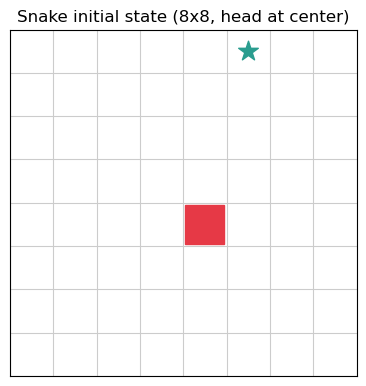

In [8]:
# Draw the snake board using the real environment's initial state (head at center, random food)
env_demo = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
obs, _ = env_demo.reset(seed=42)
snake_mask = obs[0]   # channel 0: snake body
food_mask = obs[1]    # channel 1: food

GRID = 8
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.set_xlim(0, GRID); ax.set_ylim(GRID, 0); ax.set_aspect("equal")
for i in range(GRID + 1):
    ax.axhline(i, color="#cccccc", lw=0.8)
    ax.axvline(i, color="#cccccc", lw=0.8)

# snake body (initially only the head)
for r in range(GRID):
    for c in range(GRID):
        if snake_mask[r, c]:
            ax.add_patch(plt.Rectangle((c + 0.05, r + 0.05), 0.9, 0.9, color="#e63946"))
# food
for r in range(GRID):
    for c in range(GRID):
        if food_mask[r, c]:
            ax.scatter(c + 0.5, r + 0.5, s=220, marker="*", color="#2a9d8f")

ax.set_xticks([]); ax.set_yticks([]); ax.set_title("Snake initial state (8x8, head at center)")
plt.show()
env_demo.close()

共 39 帧，最终 score=7, steps=38
已保存 snake_game.gif


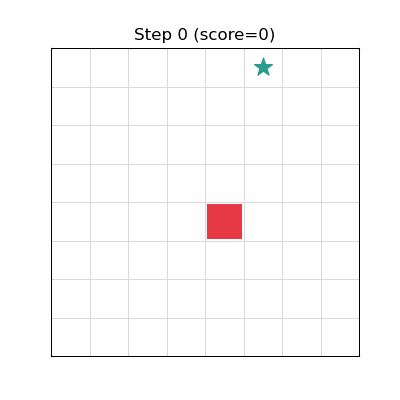

In [10]:
# Visualize a full game played by the teacher policy, and export / display the GIF
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
from IPython.display import Image, display

# 1) Play a full game with the teacher policy, recording the snake and food at every frame
env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
obs, _ = env.reset(seed=42)
snake_frames = [env.snake.copy()]
food_frames = [env.food_pos.copy()]
while True:
    obs, reward, terminated, truncated, info = env.step(env.teacher_action())
    snake_frames.append(env.snake.copy())
    food_frames.append(env.food_pos.copy())
    if terminated or truncated:
        break
env.close()
print(f"Total {len(snake_frames)} frames, final score={info['score']}, steps={info['steps']}")

# 2) Draw the board frame by frame and export a GIF
GRID = 8
fig, ax = plt.subplots(figsize=(4, 4))

def draw_frame(i):
    ax.clear()
    ax.set_xlim(0, GRID); ax.set_ylim(GRID, 0); ax.set_aspect("equal")
    for g in range(GRID + 1):
        ax.axhline(g, color="#cccccc", lw=0.5)
        ax.axvline(g, color="#cccccc", lw=0.5)
    for idx, seg in enumerate(snake_frames[i]):
        r, c = int(seg[0]), int(seg[1])
        color = "#e63946" if idx == 0 else "#f4a261"
        ax.add_patch(Rectangle((c + 0.05, r + 0.05), 0.9, 0.9, facecolor=color, edgecolor="none"))
    food = food_frames[i]
    ax.scatter(int(food[1]) + 0.5, int(food[0]) + 0.5, s=180, marker="*", color="#2a9d8f", zorder=3)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"Step {i} (score={len(snake_frames[i]) - 1})")

anim = animation.FuncAnimation(fig, draw_frame, frames=len(snake_frames), interval=200)
anim.save("snake_game.gif", writer="pillow", fps=5)
plt.close(fig)
print("Saved snake_game.gif")
display(Image(filename="snake_game.gif"))

## 1.3 Modeling state, action and reward

> **【Member 1 to fill in】** Explain the three core design decisions (also the focus of the presentation):
> 1. **Action space**: why three relative actions (left/right/straight) instead of four absolute ones (up/down/left/right).
> 2. **Observation space**: the 7-channel grid — what each channel encodes (snake, food, wall, four directions).
> 3. **Reward function** (two switchable modes, controlled by `reward_mode`). Common part: eat food +10, win +100,
>    wall/self collision −5, per-step survival −0.01.
>    - `"sparse"` (default): sparse event rewards, with an extra −0.5 penalty for looping (no shaping);
>    - `"dense"`: additionally distance shaping (closer +0.2 / farther −0.1), new-cell exploration +0.2, looping −0.4.
> The code below initializes the environment and visualizes the observation.

Action space: Discrete(3)
Observation space: Box(0.0, 1.0, (7, 8, 8), float32)
obs shape: (7, 8, 8) dtype: float32
reset info: {'score': 0, 'length': 1, 'steps': 0, 'executed_action': None}


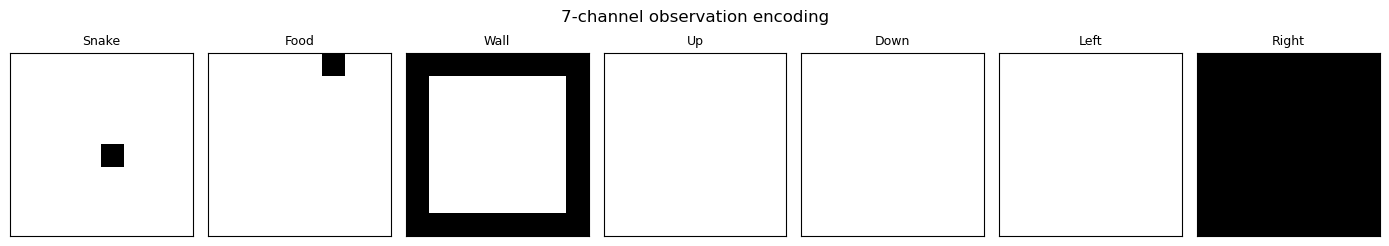

In [13]:
# Initialize the environment and inspect action / observation spaces
env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
print("Action space:", env.action_space)          # Discrete(3): 0=left, 1=right, 2=straight
print("Observation space:", env.observation_space)  # Box(7, 8, 8): 7 channels, 8x8 grid

obs, info = env.reset(seed=42)
print("obs shape:", obs.shape, "dtype:", obs.dtype)
print("reset info:", info)

# Visualize the 7 observation channels (snake / food / wall / direction)
fig, axes = plt.subplots(1, 7, figsize=(14, 2.5))
channel_names = ["Snake", "Food", "Wall", "Up", "Down", "Left", "Right"]
for i, ax in enumerate(axes):
    ax.imshow(obs[i], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(channel_names[i], fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("7-channel observation encoding")
plt.tight_layout()
plt.show()
env.close()

## 1.4 The rule-based teacher policy (one of the baselines; Member 1 presents)

> **【Member 1 to fill in and present】** Explain the idea behind `teacher_action()` (two variants, controlled by `teacher_mode`):
> - `"shortest_path"` (default): for each action, step once and use BFS to compute the true shortest path to the food
>   (treating the snake body as obstacles), then pick the action with the fewest steps; if the food is unreachable,
>   fall back to the action that maximizes reachable free space to survive longer.
> - `"legacy"`: Manhattan-distance greedy — pick the safe action closest to the food.
> This is the heuristic-rule baseline, and also the source of demonstrations for behavior cloning (Member 2).
> **Cross reference**: behavior cloning is in §2 (Member 2); evaluation as a baseline is in §5 (Member 5).

In [16]:
# Demonstrate the teacher policy: first see how it decides in the initial state, then play a full game
env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
obs, _ = env.reset(seed=42)

# Take one step to see the teacher's decision
action = env.teacher_action()
print("Initial teacher action:", action, "(0=left, 1=right, 2=straight)")
obs, reward, terminated, truncated, info = env.step(action)
print("After step: reward=%.2f | score=%s | length=%s" % (reward, info["score"], info["length"]))

# Play a full game: the teacher plays until the end
total_reward = reward
while not (terminated or truncated):
    action = env.teacher_action()
    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
print("Teacher full game: score=%s | steps=%s | total reward=%.2f" % (info["score"], info["steps"], total_reward))
env.close()

初始状态教师动作: 0 (0=左转, 1=右转, 2=直行)
执行后: 奖励=-0.01 | score=0 | length=1
教师策略一局: score=7 | steps=38 | 累计奖励=169.69


In [18]:
# Baseline evaluation: random policy vs rule-based teacher (main 8x8 setting, 100 games each)
def evaluate_baseline(policy, n_episodes=100, seed=0):
    env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
    scores = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        while True:
            action = env.action_space.sample() if policy == "random" else env.teacher_action()
            obs, reward, terminated, truncated, info = env.step(action)
            if terminated or truncated:
                scores.append(info["score"])
                break
    env.close()
    return float(np.mean(scores))

print("random baseline mean score:", evaluate_baseline("random"))
print("teacher baseline mean score:", evaluate_baseline("teacher"))

# Comparison experiment: on a dense 10x10 board with a long snake,
# compare the Manhattan-greedy teacher vs the BFS shortest-path teacher.
# Note: on the 8x8 main setting both are near-perfect and barely differ, so we use an
# extreme setting to amplify the difference.
def evaluate_teacher(mode, n_episodes=200, seed=0, grid_size=10, end_score=20, max_steps=500):
    env = SnakeEnv(grid_size=grid_size, end_score=end_score, max_steps=max_steps, teacher_mode=mode)
    scores = []; deaths = 0
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        while True:
            obs, reward, terminated, truncated, info = env.step(env.teacher_action())
            if terminated or truncated:
                scores.append(info["score"])
                if terminated and info["length"] < end_score:  # died: terminated but did not win
                    deaths += 1
                break
    env.close()
    return float(np.mean(scores)), deaths / n_episodes

legacy_score, legacy_death = evaluate_teacher("legacy")
sp_score, sp_death = evaluate_teacher("shortest_path")
print(f"legacy (Manhattan greedy) mean={legacy_score:.2f}  death rate={legacy_death:.0%}")
print(f"shortest_path (BFS)    mean={sp_score:.2f}  death rate={sp_death:.0%}")

random 基线平均分: 0.08
teacher 基线平均分: 7.0
legacy（曼哈顿贪心）  平均分=16.95  撞死率=46%
shortest_path（BFS） 平均分=18.81  撞死率=7%


---
# 2. 方法一：Actor-Critic 与行为克隆　【成员 2 负责】

## 2.1 方法原理

> **【成员 2 填写】** 讲清楚：
> 1. **行为克隆预热**：前 `teacher_episodes` 轮用规则教师（§1.4）的示范做监督学习（交叉熵），解决冷启动。
> 2. **Actor-Critic 更新**：`advantage = target − V(s)`，policy gradient 项 + critic 的 value loss + 熵正则。
> 3. 损失函数拆解（参考 `model.py` 的 `update()`）。

## 2.2 构建模型


In [ ]:
# 构建 Actor-Critic 模型（成员 2）
env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
agent_ac = ConvActorCritic(
    input_channels=env.observation_space.shape[0],
    output_dim=env.action_space.n,
    grid_size=8,
    lr=1e-4,
    weight_decay=1e-5,
    entropy_coef=0.01,
)
print(agent_ac)
env.close()

## 2.3 训练（或加载模型）

> 训练入口在 `main.py` 的 `train()`。默认 `TRAIN_MODEL=False` 时加载 checkpoint。
> **成员 2 的实质改动**：新增「有/无行为克隆预热」对照，把 `teacher_episodes` 设为 0 跑一版做对比。


In [ ]:
if TRAIN_MODEL:
    from main import TrainConfig, train
    summary_ac = train(TrainConfig(
        episodes=500,
        teacher_episodes=100,   # 成员 2 改动点：对比 0 vs 100 的预热效果
        grid_size=8,
        end_score=8,
        max_steps=300,
        seed=42,
        device="auto",
        output_dir=Path("runs/snake"),
        tensorboard=False,
    ))
    print(summary_ac)
else:
    # 加载已训练好的模型
    ckpt = Path("runs/snake/checkpoints/best.pt")
    print("加载 AC checkpoint:", ckpt, "存在:", ckpt.exists())
    # agent_ac.load_checkpoint(ckpt)  # 取消注释以加载权重

## 2.4 学习曲线

> **【成员 2 填写】** 训练过程会写 TensorBoard 事件；这里从训练返回或 `history` 里取 reward/score 画学习曲线。
> 若用 `TRAIN_MODEL=False`，请把训练时保存的曲线数据（`summary.json` / TensorBoard）读进来画图。


In [ ]:
# AC 学习曲线（成员 2：填入实际训练曲线数据）
# 示例占位：横轴 episode，纵轴 episode reward
# plt.plot(episodes, rewards); plt.xlabel("Episode"); plt.ylabel("Reward"); plt.title("AC 学习曲线")
print("TODO: 绘制 AC 学习曲线（reward / score vs episode）")


## 2.5 训练进度可视化（成员 2）

> **【成员 2 填写 + 必做】** 这是 Option 2 的明确得分点：**视觉展示玩法随训练进步**。
> 用 `save_interval` 保存的不同阶段 checkpoint（或用成员 4 提供的通用脚本），
> 渲染「早期（乱撞）vs 后期（稳定吃分）」的对比图 / GIF，并写一段文字说明观察到的进步。


In [ ]:
# AC 训练进度可视化（成员 2：加载早期/后期 checkpoint 分别渲染并排对比）
print("TODO: 渲染 AC 训练早期 vs 后期的对局对比（并排图或 GIF）")


# 3. Step-Budgeted DQN versus Double DQN

## 3.1 What we want to learn

We compare DQN with Double DQN on the common 8×8 Snake environment. We keep the architecture,
seeds, replay settings, exploration schedule, and interaction budget the same. We change only the
Bellman target. We ask three simple questions:

1. Do we get a higher score or success rate?
2. Do we get more stable results across training seeds?
3. Do the Q-value diagnostics show less estimation error?

We answer these questions separately. A better Q diagnostic does not automatically mean a better
game score.

## 3.2 How we run the notebook

- We use `MODE="smoke"` for a short pipeline check.
- We use `MODE="final"` for the frozen five-seed experiment.
- We use `MODE="analysis"` to load the completed experiment without retraining.

We reuse a run only when its `complete.json` marker exists. If one model is interrupted, we retrain
that model and keep the completed pairs.

In [1]:
# Environment setup
import importlib.util
import importlib.metadata
import gc
import json
import os
import platform
import random
import sys
import time
from dataclasses import asdict
from pathlib import Path

cwd = Path.cwd().resolve()

def find_snake_dir(start: Path):
    candidates = [
        start,
        start.parent,
        start.parent.parent,
        start / "Snake",
        start / "DSA5102-Final-Group-Project" / "Snake",
    ]
    for candidate in candidates:
        if (candidate / "environment.py").is_file() and (candidate / "dqn.py").is_file():
            return candidate
    return None

SNAKE_DIR = find_snake_dir(cwd)
if SNAKE_DIR is None:
    raise FileNotFoundError(
        "Snake source files were not found. Mount the folder containing "
        "DSA5102-Final-Group-Project into /workspace."
    )


MEMBER3_DIR = SNAKE_DIR / "member 3"
if not MEMBER3_DIR.is_dir():
    raise FileNotFoundError(f"Member 3 submission directory was not found: {MEMBER3_DIR}")

required = ["torch", "numpy", "pandas", "matplotlib", "gymnasium", "pygame", "tensorboard"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Missing packages in the active container: " + ", ".join(missing))

os.chdir(SNAKE_DIR)
if str(SNAKE_DIR) not in sys.path:
    sys.path.insert(0, str(SNAKE_DIR))

print("Python:", sys.executable)
print("Experiment directory:", SNAKE_DIR)

Python: /usr/local/bin/python
Experiment directory: /workspace/DSA5102-Final-Group-Project/Snake


## 3.3 Our fixed protocol

We use 210,000 environment steps per model. The old 3,000-episode runs used about
200,000–215,000 steps, so this gives us a similar but fairer budget. We decay ε by step,
not by episode. We also keep validation seeds separate from final test seeds.

In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

from environment import SnakeEnv
from dqn import DQNAgent, ReplayBuffer
from benchmark import load_dqn
from benchmark_double_dqn import evaluate_q_diagnostics
from main import choose_device, seed_everything

MODE = "analysis"  # Change to "final" only after the smoke run succeeds; use "analysis" afterward.
REUSE_COMPLETED = True

if MODE not in {"smoke", "final", "analysis"}:
    raise ValueError("MODE must be 'smoke', 'final', or 'analysis'")

GRID_SIZE = 8
END_SCORE = 8
MAX_STEPS_PER_EPISODE = 300
GAMMA = 0.99
TRAINING_SEEDS = [7, 42, 2026, 31415, 27182]
VALIDATION_SEED_BASE = 500_000
TEST_SEED_BASE = 900_000
COMMON_STATE_SEED_BASE = 800_000

if MODE == "smoke":
    ACTIVE_SEEDS = [42]
    TOTAL_ENV_STEPS = 10_000
    VALIDATION_INTERVAL = 2_000
    VALIDATION_EPISODES = 10
    TEST_EPISODES = 20
    PROGRESS_STEPS = [2_000, 5_000, 10_000]
    RUN_DIR = MEMBER3_DIR / "results" / "smoke"
else:
    ACTIVE_SEEDS = TRAINING_SEEDS
    TOTAL_ENV_STEPS = 210_000
    VALIDATION_INTERVAL = 20_000
    VALIDATION_EPISODES = 30
    TEST_EPISODES = 200
    PROGRESS_STEPS = [50_000, 100_000, 150_000, 200_000]
    RUN_DIR = MEMBER3_DIR / "results" / "final"

REPLAY_CAPACITY = 50_000
BATCH_SIZE = 128
LEARNING_STARTS = 1_000
TRAIN_INTERVAL = 4
TARGET_UPDATE_INTERVAL = 500
LEARNING_RATE = 3e-4
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 60_000 if MODE != "smoke" else 5_000
TORCH_THREADS = 1
DEVICE = choose_device("auto")

RUN_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(TORCH_THREADS)

protocol = {
    "protocol_mode": "smoke" if MODE == "smoke" else "final",
    "execution_mode": MODE,
    "grid_size": GRID_SIZE,
    "end_score": END_SCORE,
    "max_steps_per_episode": MAX_STEPS_PER_EPISODE,
    "training_seeds": ACTIVE_SEEDS,
    "total_environment_steps": TOTAL_ENV_STEPS,
    "validation_interval": VALIDATION_INTERVAL,
    "validation_episodes": VALIDATION_EPISODES,
    "test_episodes": TEST_EPISODES,
    "validation_seed_base": VALIDATION_SEED_BASE,
    "test_seed_base": TEST_SEED_BASE,
    "gamma": GAMMA,
    "epsilon_decay_steps": EPSILON_DECAY_STEPS,
    "device": str(DEVICE),
}
protocol_path = RUN_DIR / "protocol.json"
if MODE == "analysis":
    if not protocol_path.is_file():
        raise FileNotFoundError(f"Analysis mode requires an existing protocol: {protocol_path}")
    stored_protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    for key in ["grid_size", "end_score", "total_environment_steps", "training_seeds"]:
        if stored_protocol.get(key) != protocol.get(key):
            raise RuntimeError(f"Stored protocol mismatch for {key}: {stored_protocol.get(key)}")
    protocol = stored_protocol
else:
    protocol_path.write_text(json.dumps(protocol, indent=2), encoding="utf-8")

environment_versions = {
    "python": sys.version,
    "platform": platform.platform(),
    **{
        package: importlib.metadata.version(package)
        for package in ["torch", "numpy", "pandas", "matplotlib", "gymnasium", "pygame"]
    },
}
environment_path = RUN_DIR / "environment_versions.json"
if MODE != "analysis":
    environment_path.write_text(
        json.dumps(environment_versions, indent=2), encoding="utf-8"
    )
elif not environment_path.is_file():
    raise FileNotFoundError(
        f"Analysis mode requires the frozen training environment record: {environment_path}"
    )
display(pd.Series(protocol, name="value").to_frame())

,value
protocol_mode,final
execution_mode,final
grid_size,8
end_score,8
max_steps_per_episode,300
training_seeds,"[7, 42, 2026, 31415, 27182]"
total_environment_steps,210000
validation_interval,20000
validation_episodes,30
test_episodes,200


## 3.4 Training functions

We evaluate a greedy policy on fixed validation seeds. We select the checkpoint with the highest
mean validation score. Success rate and reward break ties. We save the checkpoint before a target
sync when both events happen on the same step. This keeps the online and target networks different
for our later diagnostics.

In [3]:
def epsilon_at_step(total_steps):
    fraction = min(max(total_steps, 0) / EPSILON_DECAY_STEPS, 1.0)
    return EPSILON_START + fraction * (EPSILON_END - EPSILON_START)


@torch.no_grad()
def evaluate_agent(agent, episodes, seed_base):
    env = SnakeEnv(grid_size=GRID_SIZE, end_score=END_SCORE,
                   max_steps=MAX_STEPS_PER_EPISODE)
    rng = random.Random(seed_base)
    rewards, scores, steps = [], [], []
    successes = 0
    was_training = agent.online.training
    agent.online.eval()
    try:
        for episode in range(episodes):
            observation, _ = env.reset(seed=seed_base + episode)
            total_reward = 0.0
            while True:
                action = agent.select_action(observation, epsilon=0.0, random_source=rng)
                observation, reward, terminated, truncated, info = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    rewards.append(total_reward)
                    scores.append(int(info["score"]))
                    steps.append(int(info["steps"]))
                    successes += int(info["length"] >= END_SCORE)
                    break
    finally:
        env.close()
        agent.online.train(was_training)
    return {
        "reward": float(np.mean(rewards)),
        "score": float(np.mean(scores)),
        "score_std_episode": float(np.std(scores, ddof=1)) if episodes > 1 else 0.0,
        "success_rate": successes / episodes,
        "mean_steps": float(np.mean(steps)),
    }


def checkpoint_config(double_dqn, seed):
    return {
        "grid_size": GRID_SIZE,
        "end_score": END_SCORE,
        "max_steps": MAX_STEPS_PER_EPISODE,
        "double_dqn": double_dqn,
        "dueling": False,
        "learning_rate": LEARNING_RATE,
        "weight_decay": 0.0,
        "gamma": GAMMA,
        "seed": seed,
        "total_environment_steps": TOTAL_ENV_STEPS,
        "epsilon_decay_steps": EPSILON_DECAY_STEPS,
    }


def train_step_budget(seed, double_dqn, run_dir):
    algorithm = "double_dqn" if double_dqn else "dqn"
    complete_path = run_dir / "complete.json"
    best_path = run_dir / "checkpoints" / "best.pt"
    latest_path = run_dir / "checkpoints" / "latest.pt"
    history_path = run_dir / "history.json"

    if REUSE_COMPLETED and complete_path.is_file() and best_path.is_file() and history_path.is_file():
        completed = json.loads(complete_path.read_text(encoding="utf-8"))
        compatible = (
            completed.get("seed") == seed
            and completed.get("algorithm") == algorithm
            and completed.get("total_steps") == TOTAL_ENV_STEPS
        )
        if compatible:
            print(f"Reusing completed run: seed={seed}, algorithm={algorithm}")
            return completed
        raise RuntimeError(
            f"Existing completion marker is incompatible with the current protocol: {complete_path}. "
            "Use a new RUN_DIR instead of mixing experiments."
        )

    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / "checkpoints").mkdir(exist_ok=True)
    seed_everything(seed)
    rng = random.Random(seed)
    env = SnakeEnv(grid_size=GRID_SIZE, end_score=END_SCORE,
                   max_steps=MAX_STEPS_PER_EPISODE)
    agent = DQNAgent(
        input_channels=env.observation_space.shape[0],
        action_count=env.action_space.n,
        grid_size=GRID_SIZE,
        learning_rate=LEARNING_RATE,
        device=DEVICE,
    )
    replay = ReplayBuffer(REPLAY_CAPACITY, seed=seed)
    history = {"train_step": [], "train_reward": [], "train_score": [],
               "epsilon": [], "validation": []}
    total_steps = 0
    episode = 0
    next_validation = VALIDATION_INTERVAL
    pending_progress = list(PROGRESS_STEPS)
    best_key = (-float("inf"), -float("inf"), -float("inf"))
    best_step = None
    started = time.perf_counter()

    try:
        while total_steps < TOTAL_ENV_STEPS:
            observation, _ = env.reset(seed=seed + episode)
            episode_reward = 0.0
            score = 0
            while total_steps < TOTAL_ENV_STEPS:
                epsilon = epsilon_at_step(total_steps)
                action = agent.select_action(observation, epsilon=epsilon, random_source=rng)
                next_observation, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated
                replay.append(observation, action, reward, next_observation, done)
                observation = next_observation
                episode_reward += reward
                score = int(info["score"])
                total_steps += 1

                ready = total_steps >= LEARNING_STARTS and len(replay) >= BATCH_SIZE
                if ready and total_steps % TRAIN_INTERVAL == 0:
                    agent.update(replay.sample(BATCH_SIZE, DEVICE), GAMMA,
                                 double_dqn=double_dqn)
                while pending_progress and total_steps >= pending_progress[0]:
                    milestone = pending_progress.pop(0)
                    agent.save_checkpoint(
                        run_dir / "checkpoints" / f"step-{milestone}.pt",
                        episode=episode, total_steps=total_steps,
                        config=checkpoint_config(double_dqn, seed),
                    )

                if total_steps >= next_validation or total_steps == TOTAL_ENV_STEPS:
                    metrics = evaluate_agent(agent, VALIDATION_EPISODES, VALIDATION_SEED_BASE)
                    metrics["step"] = total_steps
                    history["validation"].append(metrics)
                    key = (metrics["score"], metrics["success_rate"], metrics["reward"])
                    if key > best_key:
                        best_key = key
                        best_step = total_steps
                        agent.save_checkpoint(
                            best_path, episode=episode, total_steps=total_steps,
                            config=checkpoint_config(double_dqn, seed),
                        )
                    print(
                        f"seed={seed} algorithm={algorithm} step={total_steps}/{TOTAL_ENV_STEPS} "
                        f"val_score={metrics['score']:.2f} "
                        f"val_success={metrics['success_rate']:.0%} epsilon={epsilon:.3f}"
                    )
                    next_validation += VALIDATION_INTERVAL
                    history_path.write_text(json.dumps(history, indent=2), encoding="utf-8")

                # Validate and save the checkpoint before a scheduled target sync.
                # Otherwise every validation checkpoint would contain identical online
                # and target networks, making selection-gap diagnostics identically zero.
                if total_steps % TARGET_UPDATE_INTERVAL == 0:
                    agent.sync_target()

                if done:
                    break

            history["train_step"].append(total_steps)
            history["train_reward"].append(float(episode_reward))
            history["train_score"].append(score)
            history["epsilon"].append(float(epsilon_at_step(total_steps)))
            episode += 1
    finally:
        env.close()

    agent.save_checkpoint(latest_path, episode=episode - 1, total_steps=total_steps,
                          config=checkpoint_config(double_dqn, seed))
    history_path.write_text(json.dumps(history, indent=2), encoding="utf-8")
    summary = {
        "seed": seed,
        "algorithm": algorithm,
        "total_steps": total_steps,
        "episodes": episode,
        "best_validation_step": best_step,
        "best_validation_score": best_key[0],
        "train_seconds": time.perf_counter() - started,
        "best_checkpoint": str(best_path),
    }
    complete_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return summary

## 3.5 Paired training and an early visual check

We train DQN and Double DQN with the same five seeds. We also give them the same number of
environment steps. The first plot appears as soon as all paired runs are available. It lets us
check checkpoint quality and compute cost before we move to the final analysis.

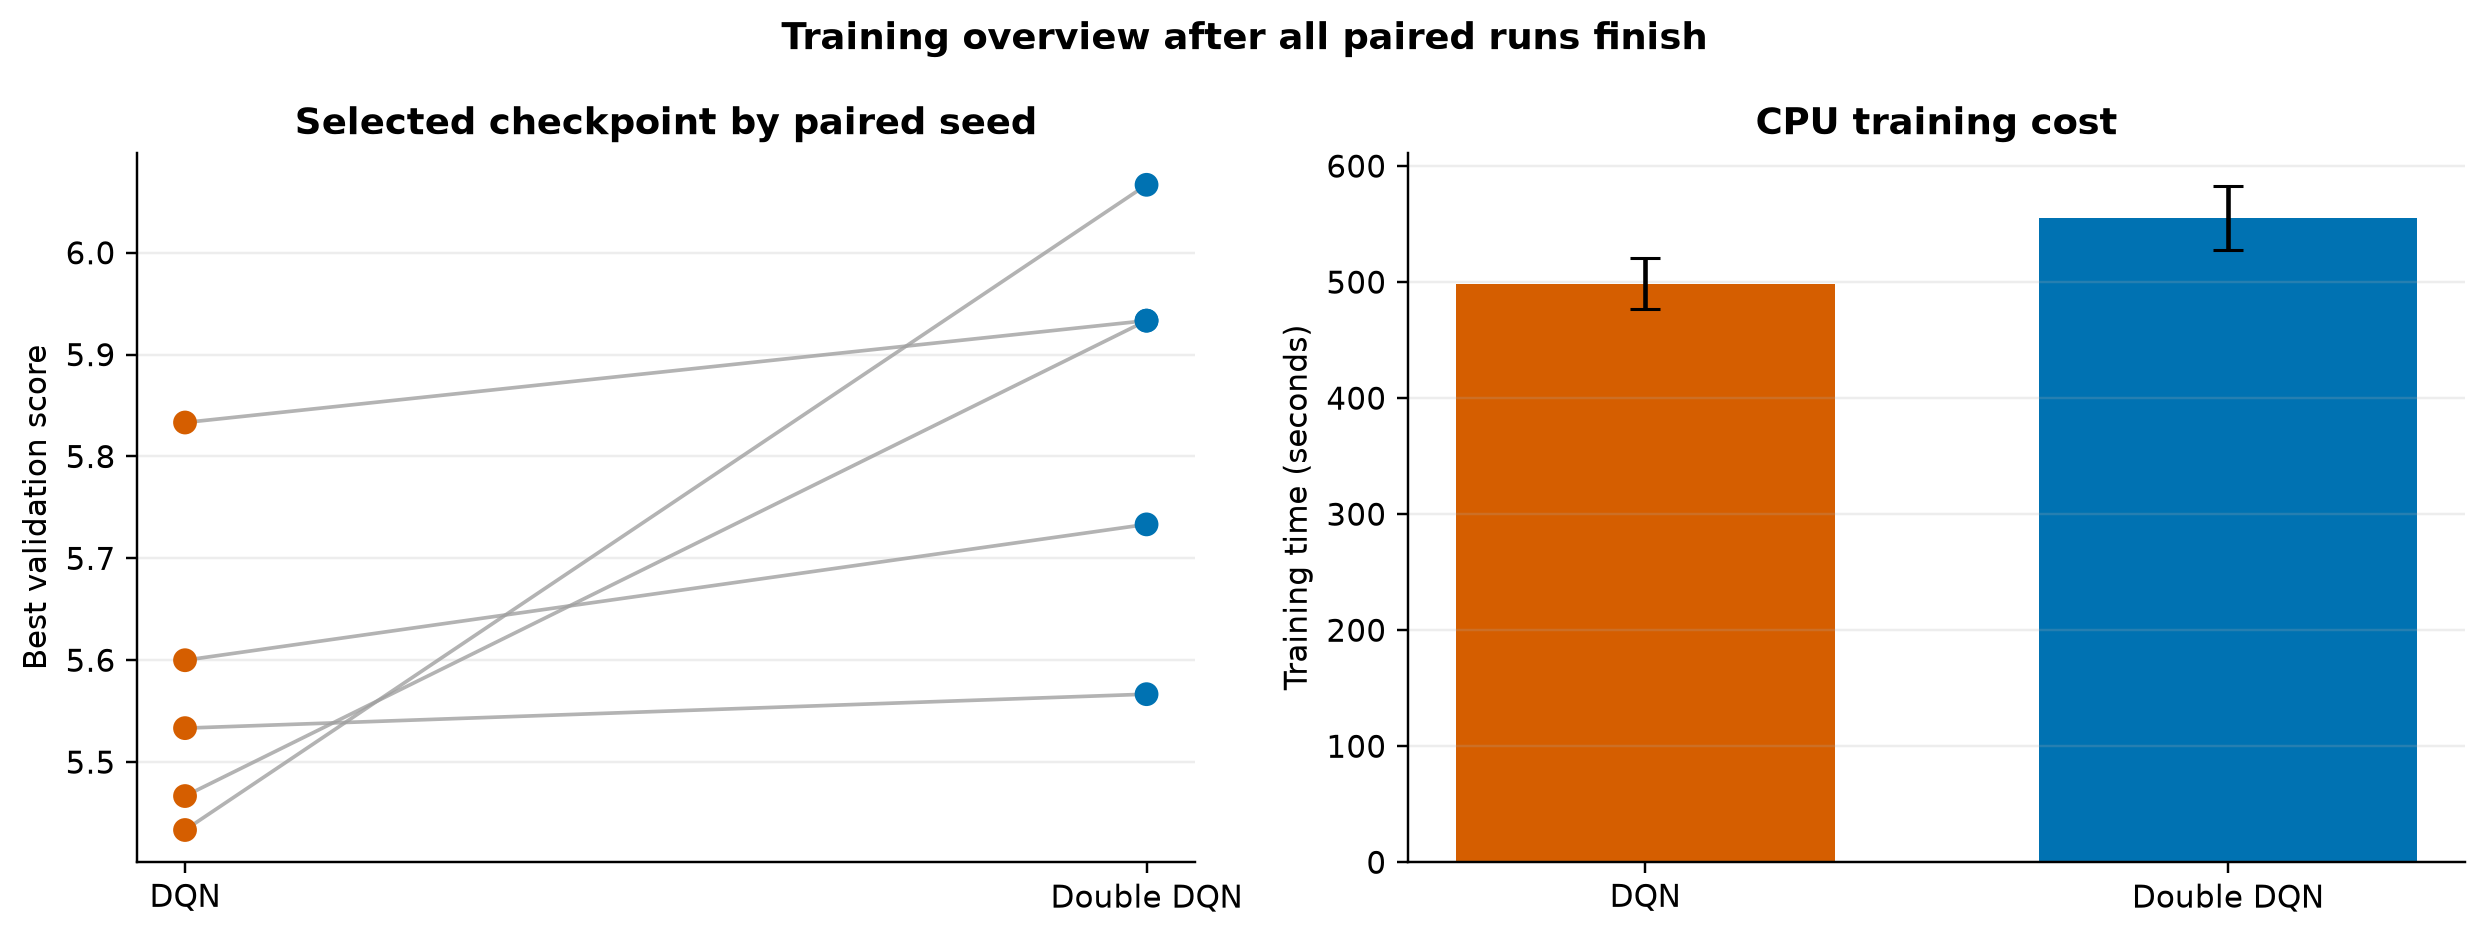

In [4]:
training_summaries = []
for seed in ACTIVE_SEEDS:
    for algorithm, use_double, dirname in [
        ("dqn", False, "dqn"),
        ("double_dqn", True, "double-dqn"),
    ]:
        model_dir = RUN_DIR / f"seed-{seed}" / dirname
        if MODE == "analysis":
            complete_path = model_dir / "complete.json"
            if not complete_path.is_file():
                raise FileNotFoundError(f"Missing completed run: {complete_path}")
            summary = json.loads(complete_path.read_text(encoding="utf-8"))
        else:
            summary = train_step_budget(seed, use_double, model_dir)
        training_summaries.append(summary)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

training_summaries = pd.DataFrame(training_summaries)
display(training_summaries)
training_summaries.to_csv(RUN_DIR / "training_summaries.csv", index=False)

,seed,algorithm,total_steps,episodes,best_validation_step,best_validation_score,train_seconds,best_checkpoint
0,7,dqn,210000,5250,200000,5.533333,484.113179,runs/member3-step-budget-v2/final/seed-7/dqn/c...
1,7,double_dqn,210000,5669,200000,5.566667,544.218100,runs/member3-step-budget-v2/final/seed-7/doubl...
2,42,dqn,210000,5996,210000,5.833333,481.622279,runs/member3-step-budget-v2/final/seed-42/dqn/...
3,42,double_dqn,210000,6144,210000,5.933333,533.467204,runs/member3-step-budget-v2/final/seed-42/doub...
4,2026,dqn,210000,5763,210000,5.433333,494.516322,runs/member3-step-budget-v2/final/seed-2026/dq...
5,2026,double_dqn,210000,6217,210000,6.066667,603.062049,runs/member3-step-budget-v2/final/seed-2026/do...
6,31415,dqn,210000,4950,200000,5.466667,535.756234,runs/member3-step-budget-v2/final/seed-31415/d...
7,31415,double_dqn,210000,5747,200000,5.933333,544.276805,runs/member3-step-budget-v2/final/seed-31415/d...
8,27182,dqn,210000,5278,200000,5.600000,497.855211,runs/member3-step-budget-v2/final/seed-27182/d...
9,27182,double_dqn,210000,5897,200000,5.733333,550.068060,runs/member3-step-budget-v2/final/seed-27182/d...


In [ ]:
# We visualize checkpoint quality and compute cost as soon as paired training is available.
training_plot = training_summaries.copy()
wide_training = training_plot.pivot(index="seed", columns="algorithm")
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.3))
for seed in wide_training.index:
    values = [
        wide_training.loc[seed, ("best_validation_score", "dqn")],
        wide_training.loc[seed, ("best_validation_score", "double_dqn")],
    ]
    axes[0].plot([0, 1], values, color="#A0A0A0", lw=1.2, alpha=0.8)
    axes[0].scatter([0, 1], values, s=46, color=["#D55E00", "#0072B2"], zorder=3)
axes[0].set_xticks([0, 1], ["DQN", "Double DQN"])
axes[0].set_ylabel("Best validation score")
axes[0].set_title("Selected checkpoint by paired seed", weight="bold")

time_summary = (training_plot.assign(
    label=training_plot.algorithm.map({"dqn": "DQN", "double_dqn": "Double DQN"})
).groupby("label")["train_seconds"].agg(["mean", "std"]).reindex(["DQN", "Double DQN"]))
axes[1].bar([0, 1], time_summary["mean"], yerr=time_summary["std"], capsize=5,
            color=["#D55E00", "#0072B2"], width=0.65)
axes[1].set_xticks([0, 1], ["DQN", "Double DQN"])
axes[1].set_ylabel("Training time (seconds)")
axes[1].set_title("CPU training cost", weight="bold")
for ax in axes:
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Training overview after all paired runs finish", weight="bold")
fig.tight_layout()
fig.savefig(RUN_DIR / "training_overview.png", dpi=220, bbox_inches="tight")
plt.show()

## 3.6 Shared held-out states

Each model visits different states when it follows its own policy. We therefore build one shared
state set from Random, legacy-teacher, and BFS-teacher trajectories. We use the same observations
for every trained model. This makes our online/target comparison easier to interpret.

In [5]:
def collect_common_states(max_states=1500):
    env = SnakeEnv(grid_size=GRID_SIZE, end_score=END_SCORE,
                   max_steps=MAX_STEPS_PER_EPISODE)
    rng = random.Random(COMMON_STATE_SEED_BASE)
    states = []
    policies = ["random", "legacy", "shortest_path"]
    try:
        episode = 0
        while len(states) < max_states:
            mode = policies[episode % len(policies)]
            env.teacher_mode = mode if mode != "random" else "shortest_path"
            observation, _ = env.reset(seed=COMMON_STATE_SEED_BASE + episode)
            while len(states) < max_states:
                states.append(observation.copy())
                action = rng.randrange(env.action_space.n) if mode == "random" else env.teacher_action()
                observation, _, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break
            episode += 1
    finally:
        env.close()
    return np.stack(states)


@torch.no_grad()
def common_state_diagnostics(agent, states):
    selection_gaps = []
    disagreements = 0
    for start in range(0, len(states), 512):
        batch = torch.from_numpy(states[start:start + 512]).to(DEVICE, dtype=torch.float32)
        online_actions = agent.online(batch).argmax(dim=1, keepdim=True)
        target_values = agent.target(batch)
        target_actions = target_values.argmax(dim=1, keepdim=True)
        standard_values = target_values.max(dim=1).values
        double_values = target_values.gather(1, online_actions).squeeze(1)
        selection_gaps.extend((standard_values - double_values).cpu().tolist())
        disagreements += int((online_actions != target_actions).sum().item())
    return {
        "common_target_selection_gap": float(np.mean(selection_gaps)),
        "common_action_disagreement_rate": disagreements / len(states),
    }

common_states = collect_common_states()
print("Shared held-out states:", common_states.shape)

Shared held-out states: (1500, 7, 8, 8)


## 3.7 Frozen test and paired outcomes

We load the best validation checkpoint for each run. We then evaluate it on 200 untouched test
seeds. The paired plot appears immediately after this step. It shows that the average direction
favors Double DQN, but it also shows clear seed-to-seed variation.

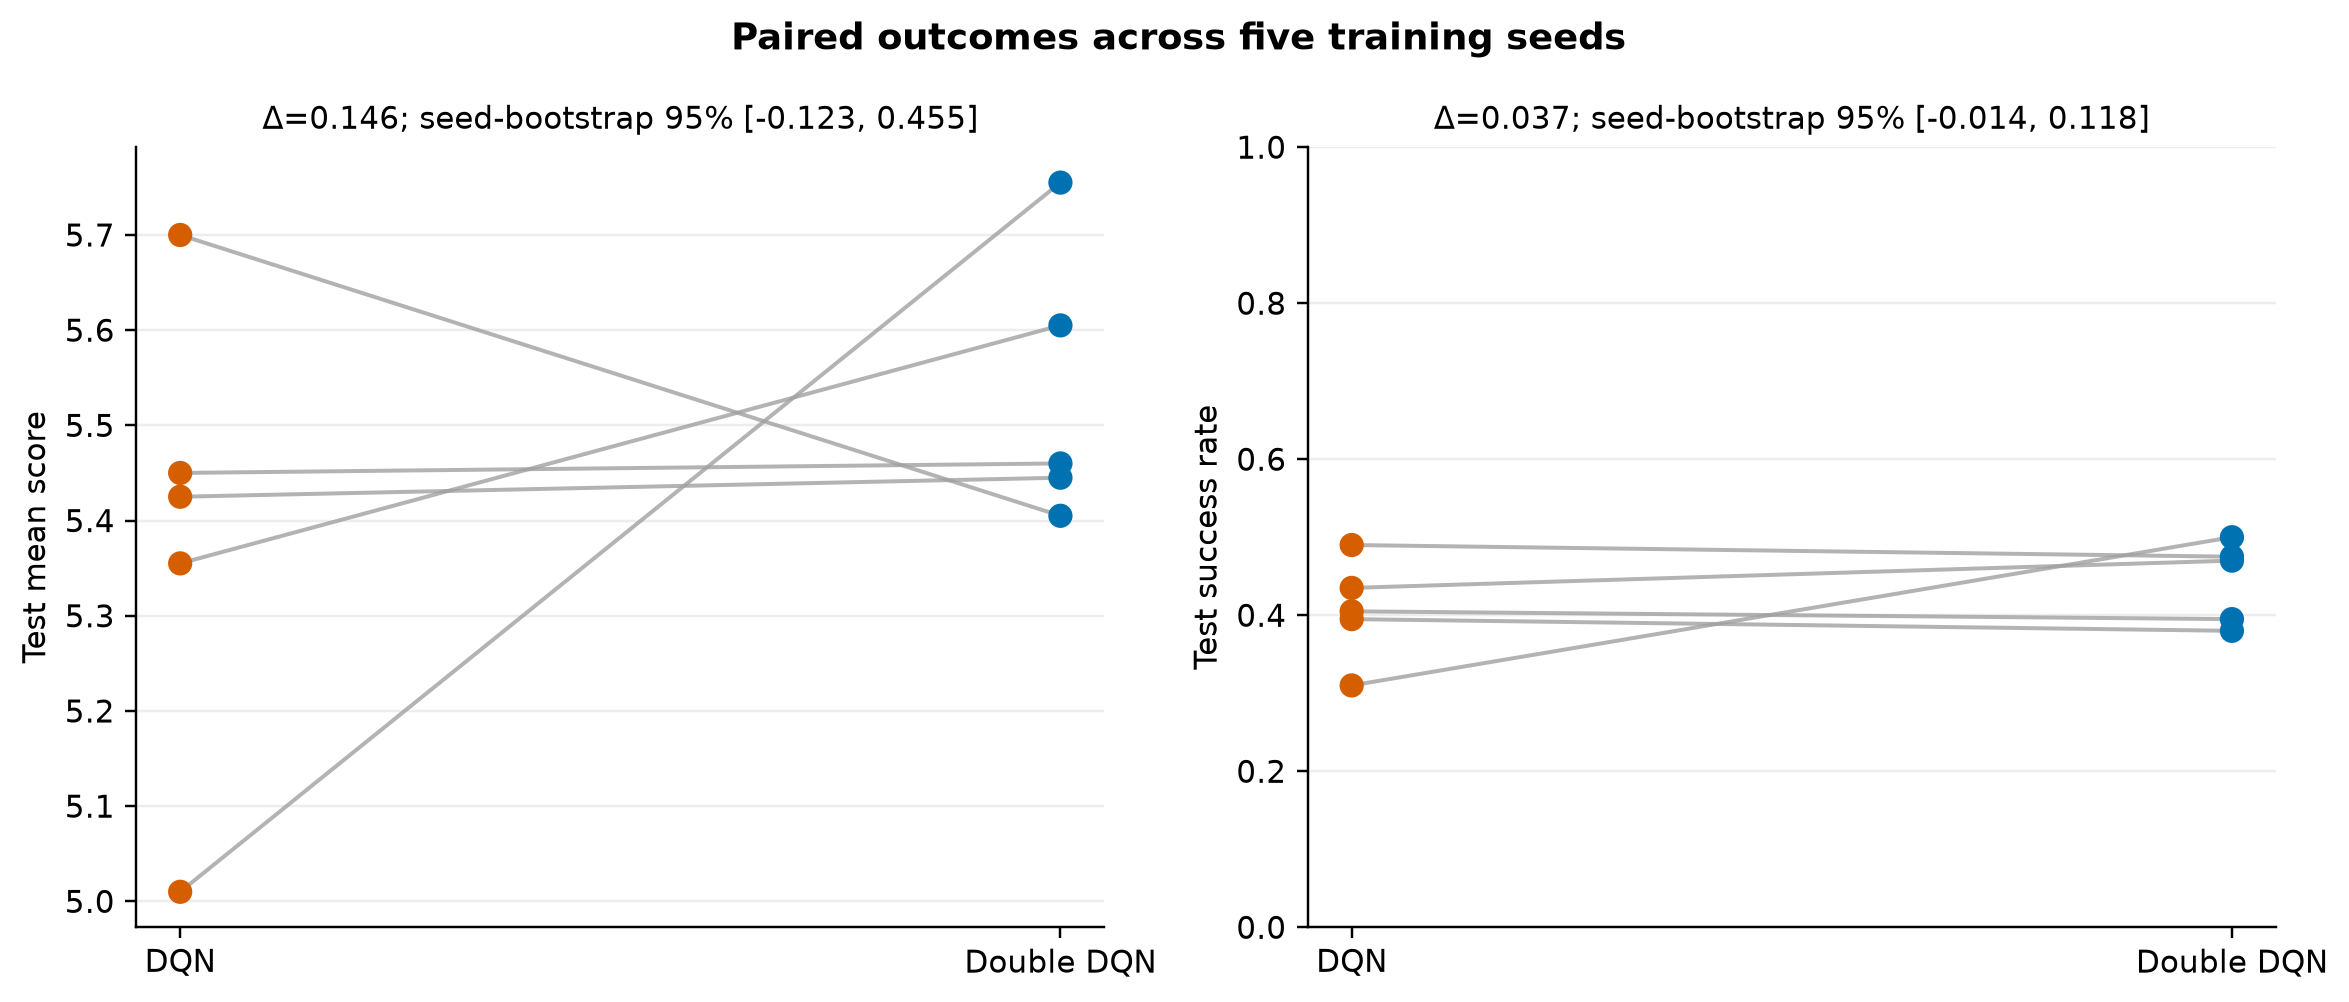

In [6]:
final_rows = []
for seed in ACTIVE_SEEDS:
    for algorithm, dirname in [("dqn", "dqn"), ("double_dqn", "double-dqn")]:
        model_dir = RUN_DIR / f"seed-{seed}" / dirname
        summary = json.loads((model_dir / "complete.json").read_text(encoding="utf-8"))
        agent = load_dqn(model_dir / "checkpoints" / "best.pt", DEVICE)
        diagnostics = evaluate_q_diagnostics(
            agent,
            grid_size=GRID_SIZE,
            end_score=END_SCORE,
            max_steps=MAX_STEPS_PER_EPISODE,
            episodes=TEST_EPISODES,
            seed_base=TEST_SEED_BASE,
            gamma=GAMMA,
        )
        common = common_state_diagnostics(agent, common_states)
        final_rows.append({
            "seed": seed,
            "algorithm": algorithm,
            "best_validation_step": summary["best_validation_step"],
            "train_seconds": summary["train_seconds"],
            **diagnostics,
            **common,
        })
        del agent
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

results = pd.DataFrame(final_rows)
display(results.round(4))
results.to_csv(RUN_DIR / "final_results.csv", index=False)
(RUN_DIR / "final_results.json").write_text(
    json.dumps({"protocol": protocol, "runs": final_rows}, indent=2), encoding="utf-8"
)

,seed,algorithm,best_validation_step,train_seconds,reward,score,success_rate,initial_q_mean,discounted_return_mean,q_return_gap_mean,q_return_gap_abs_mean,q_overestimate_rate,target_selection_gap_mean,action_disagreement_rate,common_target_selection_gap,common_action_disagreement_rate
0,7,dqn,200000,484.1132,88.4134,5.425,0.405,63.7578,66.0534,-2.2955,40.2739,0.595,0.0760,0.1486,0.0646,0.1327
1,7,double_dqn,200000,544.2181,88.2183,5.445,0.395,64.1332,65.9933,-1.8601,39.9568,0.605,0.0683,0.1456,0.0576,0.1067
2,42,dqn,210000,481.6223,102.8766,5.700,0.490,71.2806,75.0451,-3.7645,41.5184,0.510,0.0879,0.1698,0.0669,0.1427
3,42,double_dqn,210000,533.4672,95.2985,5.405,0.475,68.8594,70.8251,-1.9656,44.0553,0.525,0.1123,0.2034,0.0420,0.0920
4,2026,dqn,210000,494.5163,88.0079,5.355,0.435,77.0932,66.7421,10.3511,44.7499,0.565,0.1424,0.2840,0.0649,0.1260
5,2026,double_dqn,210000,603.0620,99.4048,5.605,0.470,69.5254,73.3812,-3.8557,42.4017,0.530,0.0583,0.1536,0.0392,0.1040
6,31415,dqn,200000,535.7562,89.1627,5.450,0.395,44.4126,65.3298,-20.9172,34.7999,0.485,0.0857,0.1523,0.0579,0.1173
7,31415,double_dqn,200000,544.2768,86.2616,5.460,0.380,55.8723,64.2325,-8.3602,35.9870,0.615,0.0798,0.1461,0.0727,0.1353
8,27182,dqn,200000,497.8552,72.0920,5.010,0.310,58.1920,56.5046,1.6874,38.2524,0.690,0.0970,0.1697,0.0603,0.1227
9,27182,double_dqn,200000,550.0681,103.7961,5.755,0.500,70.9643,76.1988,-5.2345,42.0506,0.500,0.0260,0.0838,0.0191,0.0700


7290

In [ ]:
# We inspect paired final outcomes immediately after the frozen test finishes.
wide_results = results.pivot(index="seed", columns="algorithm")
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.6))
for ax, metric, ylabel in zip(
    axes, ["score", "success_rate"], ["Test mean score", "Test success rate"]
):
    for seed in wide_results.index:
        values = [wide_results.loc[seed, (metric, "dqn")],
                  wide_results.loc[seed, (metric, "double_dqn")]]
        ax.plot([0, 1], values, color="#A0A0A0", lw=1.3, alpha=0.8)
        ax.scatter([0, 1], values, s=48, color=["#D55E00", "#0072B2"], zorder=3)
    ax.set_xticks([0, 1], ["DQN", "Double DQN"])
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_ylim(0.25, 0.55)
fig.suptitle("Paired frozen-test outcomes", weight="bold")
fig.tight_layout()
fig.savefig(RUN_DIR / "paired_final_outcomes.png", dpi=220, bbox_inches="tight")
plt.show()

## 3.8 Non-learning references

We test Random, the legacy Manhattan teacher, and the BFS teacher on the same test seeds. We use
them as reference points. The teachers are strong on this fixed board, but they are not theoretical
upper bounds.

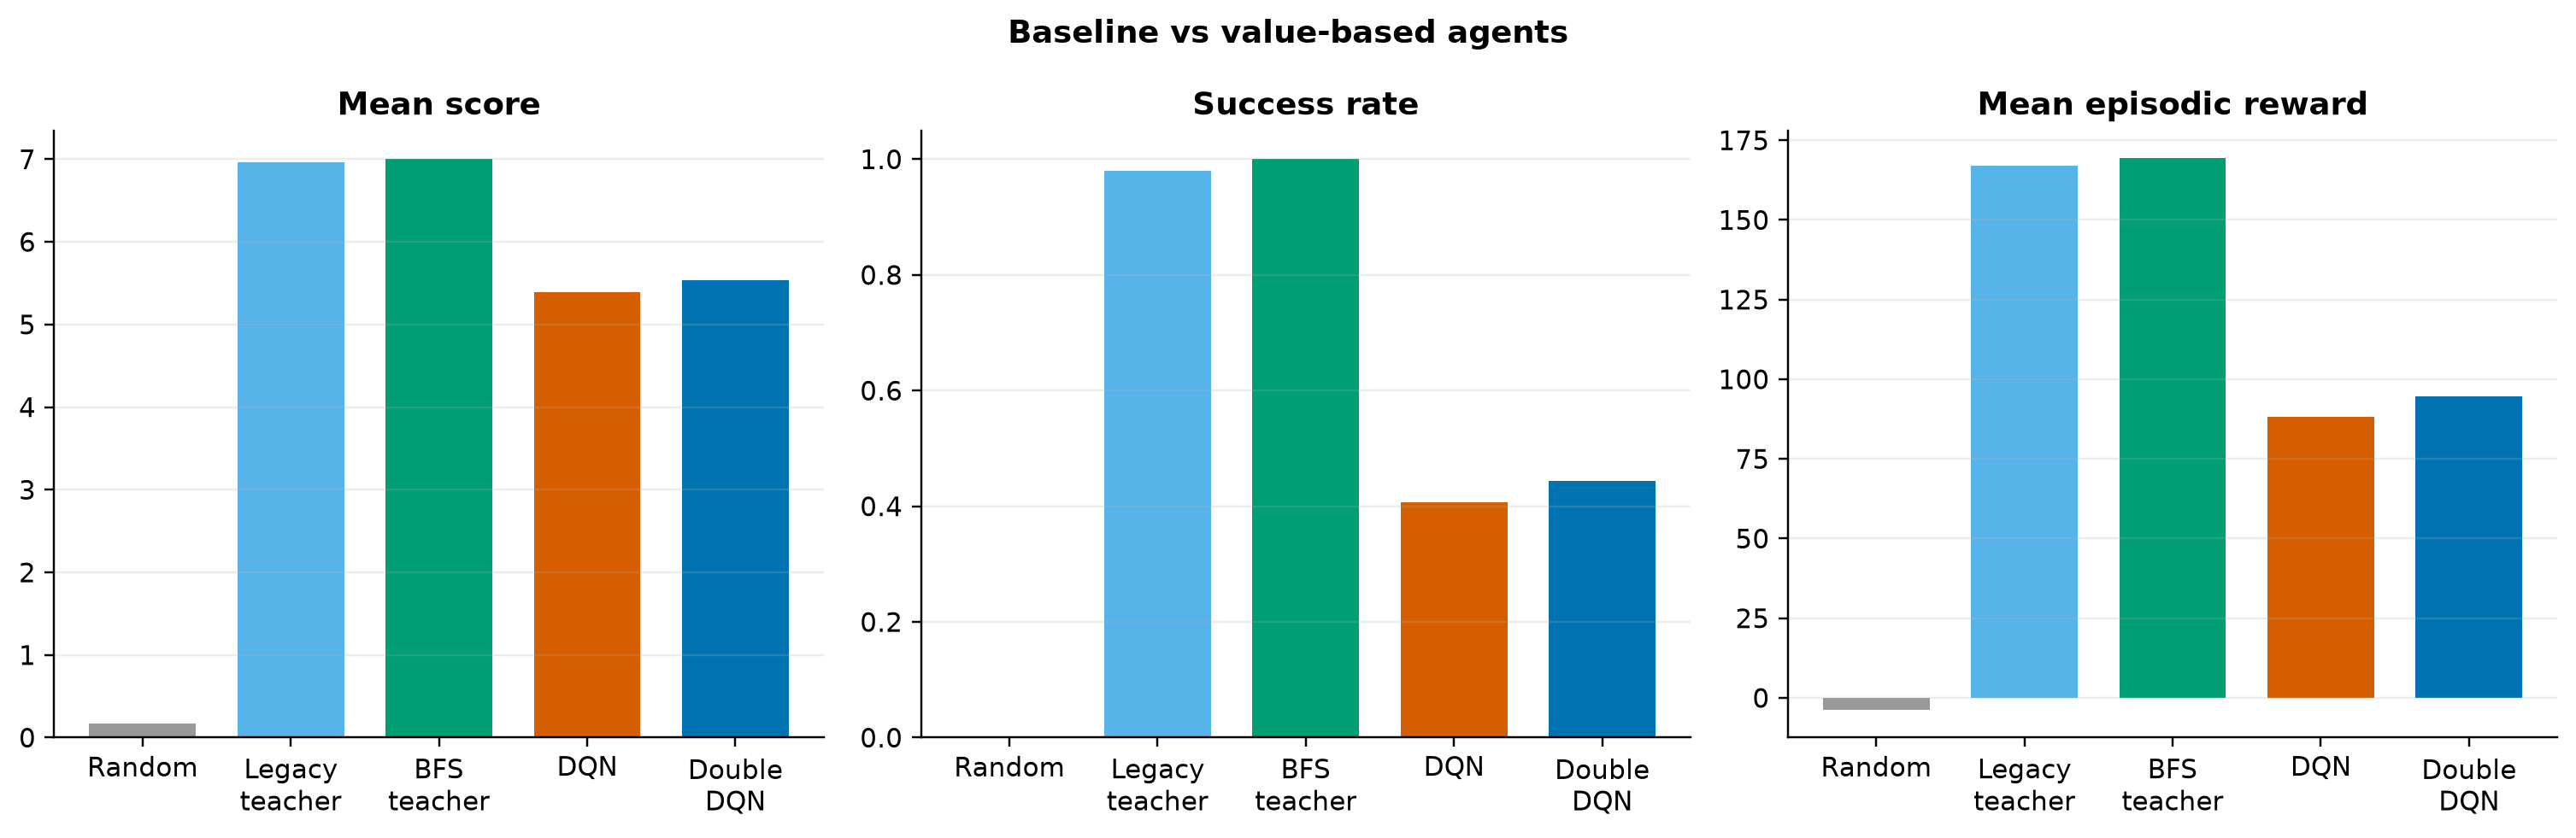

In [7]:
def evaluate_baseline(name):
    teacher_mode = "legacy" if name == "teacher_legacy" else "shortest_path"
    env = SnakeEnv(grid_size=GRID_SIZE, end_score=END_SCORE,
                   max_steps=MAX_STEPS_PER_EPISODE, teacher_mode=teacher_mode)
    rng = random.Random(TEST_SEED_BASE)
    rows = []
    try:
        for episode in range(TEST_EPISODES):
            _, _ = env.reset(seed=TEST_SEED_BASE + episode)
            total_reward = 0.0
            while True:
                action = rng.randrange(env.action_space.n) if name == "random" else env.teacher_action()
                _, reward, terminated, truncated, info = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    rows.append({
                        "strategy": name,
                        "episode": episode,
                        "reward": total_reward,
                        "score": int(info["score"]),
                        "success": int(info["length"] >= END_SCORE),
                    })
                    break
    finally:
        env.close()
    return pd.DataFrame(rows)

baseline_episodes = pd.concat(
    [evaluate_baseline("random"), evaluate_baseline("teacher_legacy"),
     evaluate_baseline("teacher_bfs")], ignore_index=True
)
baseline_summary = baseline_episodes.groupby("strategy").agg(
    reward=("reward", "mean"), score=("score", "mean"),
    success_rate=("success", "mean"), score_std_episode=("score", "std")
).reset_index()
display(baseline_summary.round(4))
baseline_episodes.to_csv(RUN_DIR / "baseline_test_episodes.csv", index=False)

,strategy,reward,score,success_rate,score_std_episode
0,random,-3.8093,0.175,0.00,0.4064
1,teacher_bfs,169.4675,7.000,1.00,0.0000
2,teacher_legacy,167.0116,6.965,0.98,0.2723


In [ ]:
# We place the learned agents next to the non-learning references.
learned_summary = results.groupby("algorithm").agg(
    reward=("reward", "mean"), score=("score", "mean"),
    success_rate=("success_rate", "mean")
)
baseline_for_plot = baseline_summary.set_index("strategy")[["reward", "score", "success_rate"]]
order = ["random", "teacher_legacy", "teacher_bfs", "dqn", "double_dqn"]
comparison = pd.concat([baseline_for_plot, learned_summary]).loc[order]
labels = ["Random", "Legacy\nteacher", "BFS\nteacher", "DQN", "Double\nDQN"]
palette = ["#999999", "#56B4E9", "#009E73", "#D55E00", "#0072B2"]
fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.5))
for ax, metric, title in zip(
    axes, ["score", "success_rate", "reward"],
    ["Mean score", "Success rate", "Mean episodic reward"]
):
    values = comparison[metric].to_numpy(float)
    ax.bar(np.arange(len(values)), values, color=palette, width=0.72)
    ax.set_xticks(np.arange(len(values)), labels)
    ax.set_title(title, weight="bold")
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_ylim(0, 1.05)
fig.suptitle("Baseline vs value-based agents", weight="bold")
fig.tight_layout()
fig.savefig(RUN_DIR / "baseline_vs_agents.png", dpi=220, bbox_inches="tight")
plt.show()

## 3.9 Paired uncertainty and Q diagnostics

We treat the training seed as the experimental unit. We bootstrap the five paired seed differences.
The 95% intervals for score and success rate both include zero. We therefore describe the gameplay
gain as a positive trend, not a decisive advantage.

The Q results are also mixed. Double DQN has a more stable signed Q-return gap, but its absolute
gap does not improve. Its online and target networks disagree on fewer actions in the shared state
set. We take this as evidence of more consistent action selection, not proof of perfect Q values.

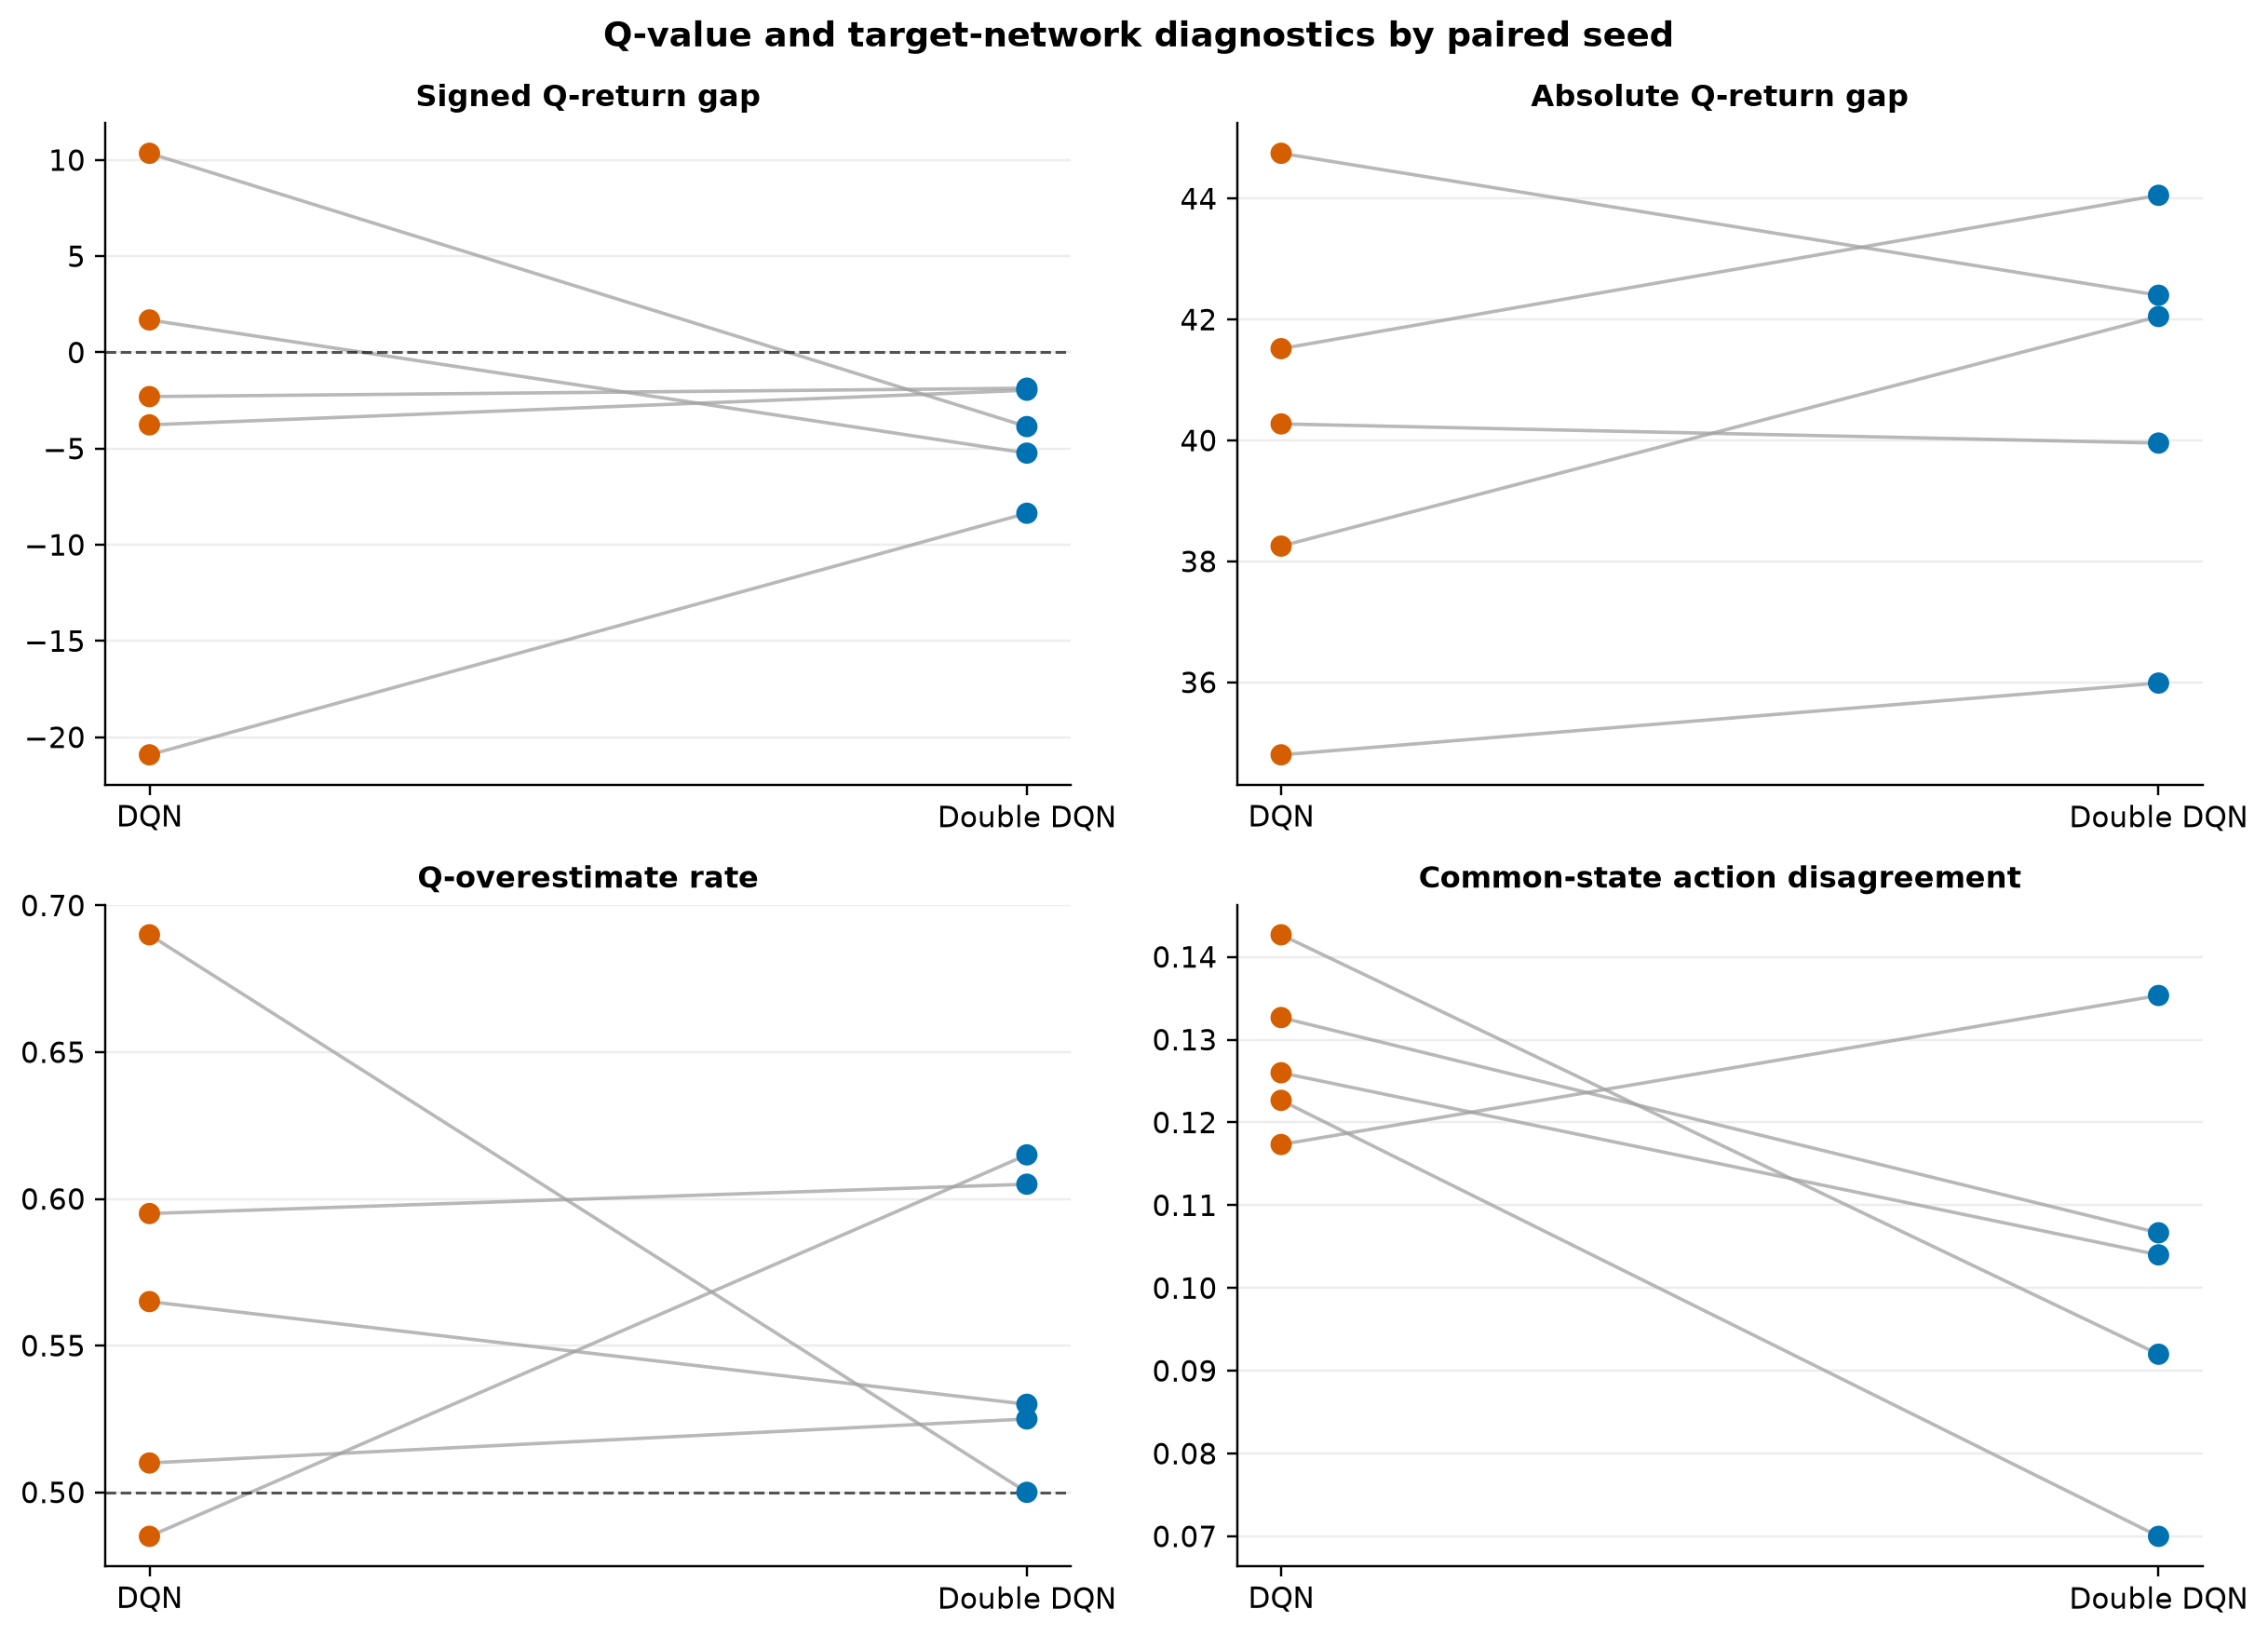

In [8]:
paired = results.pivot(index="seed", columns="algorithm")
metrics = ["score", "success_rate", "q_return_gap_mean",
           "q_return_gap_abs_mean", "q_overestimate_rate",
           "common_target_selection_gap", "common_action_disagreement_rate"]
paired_rows = []
for seed in ACTIVE_SEEDS:
    row = {"seed": seed}
    for metric in metrics:
        row[f"delta_{metric}"] = (
            paired.loc[seed, (metric, "double_dqn")] - paired.loc[seed, (metric, "dqn")]
        )
    paired_rows.append(row)
paired_differences = pd.DataFrame(paired_rows)
display(paired_differences.round(4))
paired_differences.to_csv(RUN_DIR / "paired_differences.csv", index=False)

def bootstrap_mean_ci(values, seed=12345, resamples=20_000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(resamples, len(values)), replace=True).mean(axis=1)
    return float(values.mean()), float(np.quantile(samples, 0.025)), float(np.quantile(samples, 0.975))

bootstrap_rows = []
for metric in metrics:
    mean, low, high = bootstrap_mean_ci(paired_differences[f"delta_{metric}"])
    bootstrap_rows.append({"metric": metric, "mean_delta_ddqn_minus_dqn": mean,
                           "bootstrap_95_low": low, "bootstrap_95_high": high})
bootstrap_summary = pd.DataFrame(bootstrap_rows)
display(bootstrap_summary.round(4))
bootstrap_summary.to_csv(RUN_DIR / "paired_bootstrap_summary.csv", index=False)

,seed,delta_score,delta_success_rate,delta_q_return_gap_mean,delta_q_return_gap_abs_mean,delta_q_overestimate_rate,delta_common_target_selection_gap,delta_common_action_disagreement_rate
0,7,0.020,-0.010,0.4354,-0.3171,0.010,-0.0070,-0.0260
1,42,-0.295,-0.015,1.7989,2.5369,0.015,-0.0249,-0.0507
2,2026,0.250,0.035,-14.2068,-2.3483,-0.035,-0.0257,-0.0220
3,31415,0.010,-0.015,12.5570,1.1871,0.130,0.0148,0.0180
4,27182,0.745,0.190,-6.9219,3.7982,-0.190,-0.0412,-0.0527


,metric,mean_delta_ddqn_minus_dqn,bootstrap_95_low,bootstrap_95_high
0,score,0.1460,-0.1230,0.4550
1,success_rate,0.0370,-0.0140,0.1180
2,q_return_gap_mean,-1.2675,-8.3789,6.5096
3,q_return_gap_abs_mean,0.9714,-0.9650,2.7715
4,q_overestimate_rate,-0.0140,-0.1100,0.0730
5,common_target_selection_gap,-0.0168,-0.0317,0.0017
6,common_action_disagreement_rate,-0.0267,-0.0465,-0.0037


In [ ]:
# We show the seed pairs instead of hiding them behind aggregate bars.
diagnostics_to_plot = [
    ("q_return_gap_mean", "Signed Q-return gap", 0.0),
    ("q_return_gap_abs_mean", "Absolute Q-return gap", None),
    ("q_overestimate_rate", "Q-overestimate rate", 0.5),
    ("common_action_disagreement_rate", "Common-state action disagreement", None),
]
wide_results = results.pivot(index="seed", columns="algorithm")
fig, axes = plt.subplots(2, 2, figsize=(11.2, 8.1))
for ax, (metric, title, reference) in zip(axes.flat, diagnostics_to_plot):
    for seed in wide_results.index:
        values = [wide_results.loc[seed, (metric, "dqn")],
                  wide_results.loc[seed, (metric, "double_dqn")]]
        ax.plot([0, 1], values, color="#A0A0A0", lw=1.2, alpha=0.75)
        ax.scatter([0, 1], values, s=42, color=["#D55E00", "#0072B2"], zorder=3)
    if reference is not None:
        ax.axhline(reference, color="black", ls="--", lw=1, alpha=0.65)
    ax.set_xticks([0, 1], ["DQN", "Double DQN"])
    ax.set_title(title, weight="bold", fontsize=10.5)
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Q-value and target-network diagnostics by paired seed", weight="bold")
fig.tight_layout()
fig.savefig(RUN_DIR / "q_diagnostics.png", dpi=220, bbox_inches="tight")
plt.show()

## 3.10 Summary

We find a small average improvement for Double DQN. Mean score increases from 5.388 to 5.534, and
success rate increases from 40.7% to 44.4%. The paired intervals include zero, so the gain is not
stable enough for a strong superiority claim. Double DQN also takes about 11% more CPU time.

We place the final validation curves below. They show how both methods improve under the same step
budget. Double DQN learns faster in the middle, but the curves are close near the end. We keep this
learning-curve view inside the summary instead of creating a separate visualization chapter.

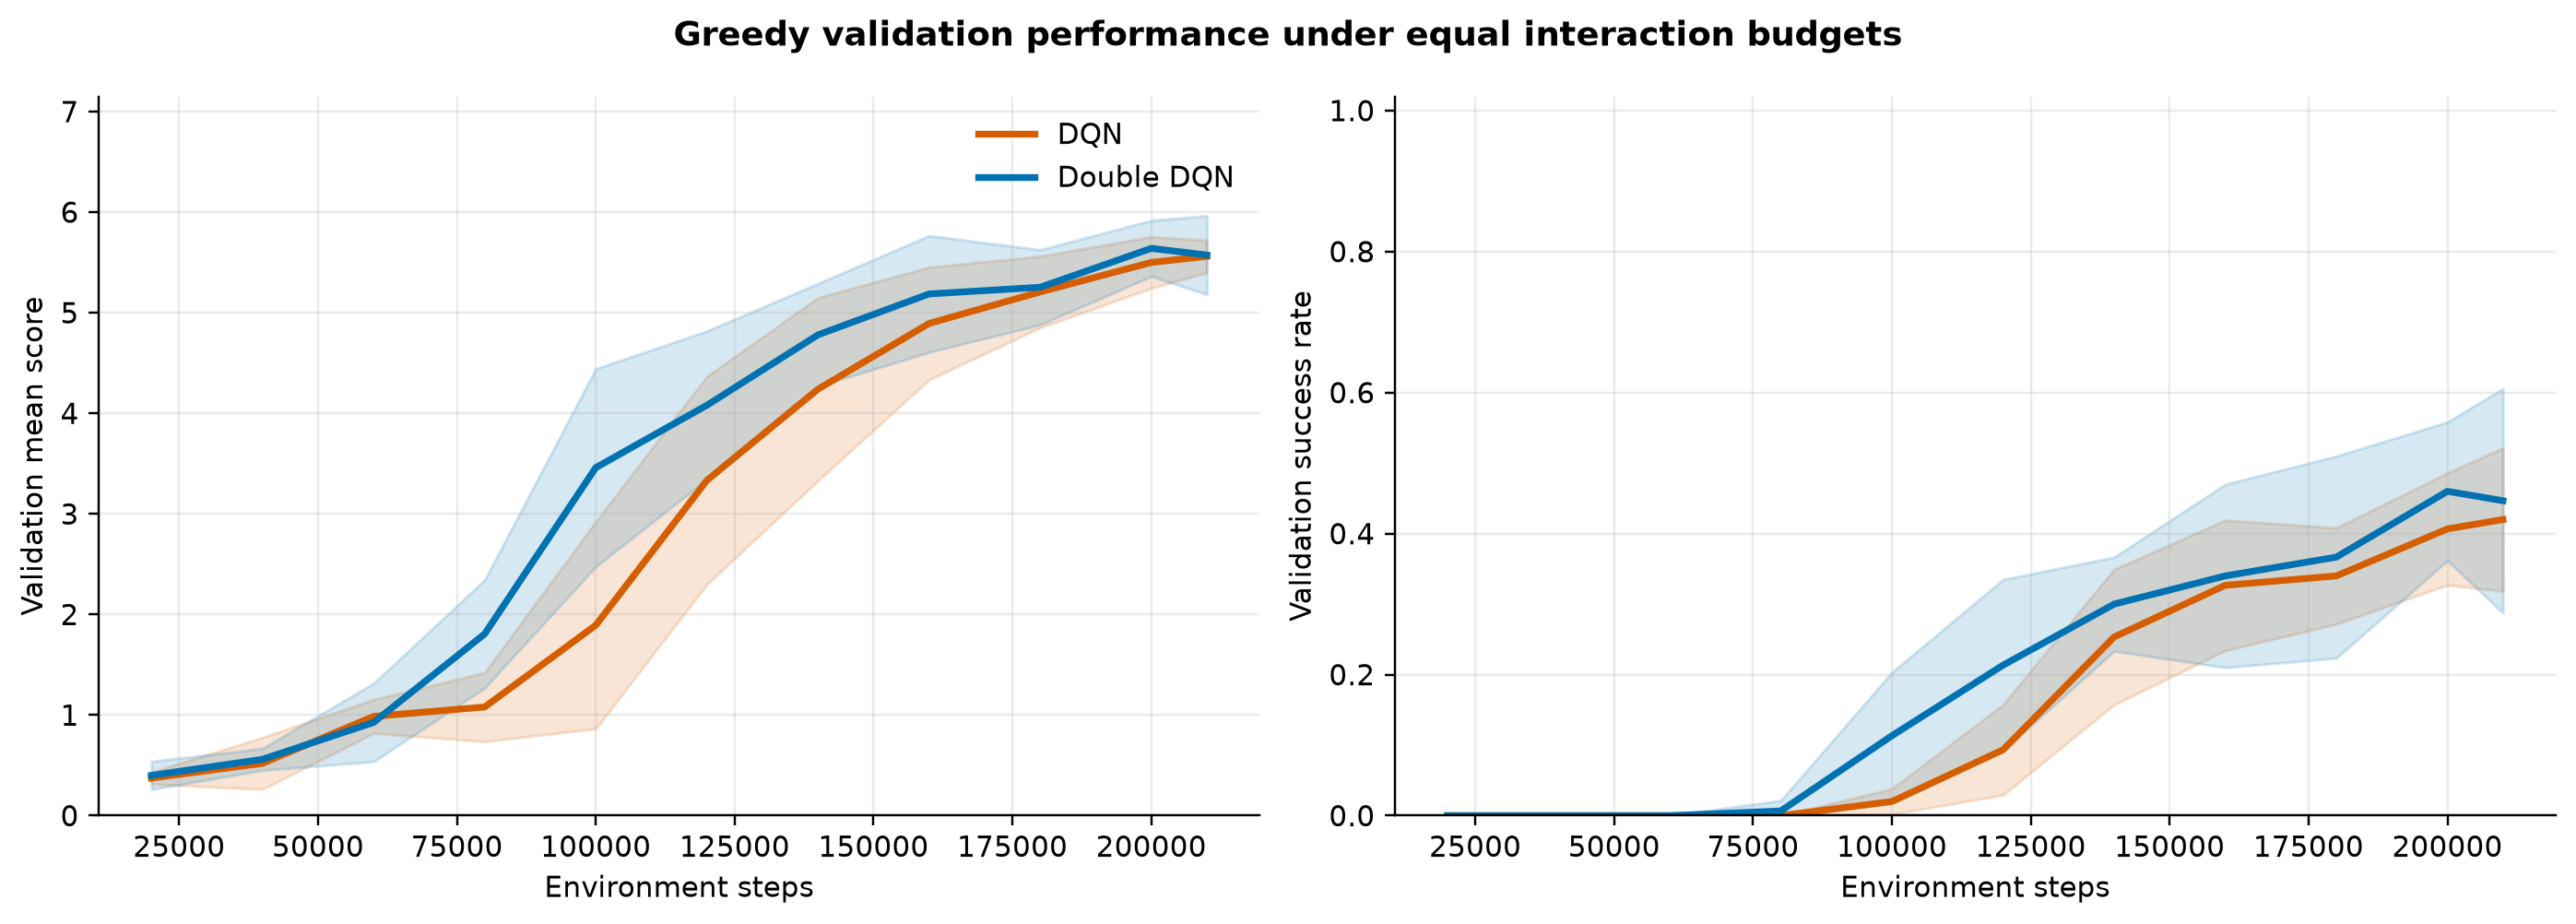

In [9]:
validation_frames = []
for seed in ACTIVE_SEEDS:
    for algorithm, dirname in [("DQN", "dqn"), ("Double DQN", "double-dqn")]:
        history = json.loads(
            (RUN_DIR / f"seed-{seed}" / dirname / "history.json").read_text(encoding="utf-8")
        )
        frame = pd.DataFrame(history["validation"])
        frame["seed"] = seed
        frame["algorithm"] = algorithm
        validation_frames.append(frame)
validation = pd.concat(validation_frames, ignore_index=True)

colors = {"DQN": "#D55E00", "Double DQN": "#0072B2"}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharex=True)
for ax, metric, ylabel in zip(
    axes, ["score", "success_rate"], ["Validation mean score", "Validation success rate"]
):
    for algorithm in ["DQN", "Double DQN"]:
        selected = validation[validation.algorithm == algorithm]
        grouped = selected.groupby("step")[metric].agg(["mean", "std"]).reset_index()
        grouped["std"] = grouped["std"].fillna(0.0)
        x = grouped["step"].to_numpy(dtype=float)
        y = grouped["mean"].to_numpy(dtype=float)
        s = grouped["std"].to_numpy(dtype=float)
        ax.plot(x, y, linewidth=2.3, color=colors[algorithm], label=algorithm)
        ax.fill_between(x, y - s, y + s, color=colors[algorithm], alpha=0.17)
    ax.set_xlabel("Environment steps")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)
axes[0].set_ylim(0, 7.2)
axes[1].set_ylim(0, 1.02)
axes[0].legend(frameon=False)
fig.suptitle("Greedy validation performance at equal interaction budgets",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(RUN_DIR / "validation_curves.png", dpi=220, bbox_inches="tight")
plt.show()

aggregate = results.groupby("algorithm").agg(
    score_mean=("score", "mean"), score_sd=("score", "std"),
    success_mean=("success_rate", "mean"), success_sd=("success_rate", "std"),
    q_gap_mean=("q_return_gap_mean", "mean"), q_gap_sd=("q_return_gap_mean", "std"),
).reset_index()
display(aggregate.round(4))
aggregate.to_csv(RUN_DIR / "aggregate_results.csv", index=False)

,algorithm,score_mean,score_sd,success_mean,success_sd,q_gap_mean,q_gap_sd
0,double_dqn,5.534,0.1448,0.444,0.0531,-4.2552,2.6902
1,dqn,5.388,0.2483,0.407,0.0656,-2.9877,11.4273


In [10]:
print("Artifacts written to:", RUN_DIR.resolve())
print("Primary files:")
for name in [
    "protocol.json", "training_summaries.csv", "final_results.csv",
    "paired_differences.csv", "paired_bootstrap_summary.csv",
    "aggregate_results.csv", "training_overview.png",
    "paired_final_outcomes.png", "baseline_vs_agents.png",
    "q_diagnostics.png", "validation_curves.png",
]:
    path = RUN_DIR / name
    print(f"  {name}: {path.is_file()}")

Artifacts written to: /workspace/DSA5102-Final-Group-Project/Snake/runs/member3-step-budget-v2/final
Primary files:
  protocol.json: True
  training_summaries.csv: True
  final_results.csv: True
  paired_differences.csv: True
  paired_bootstrap_summary.csv: True
  aggregate_results.csv: True
  validation_curves.png: True


---
# 4. 方法三：PPO　【成员 4 负责】

## 4.1 方法原理

> **【成员 4 填写】** 讲清楚：
> 1. **on-policy vs off-policy** 的区别（PPO 是 on-policy）。
> 2. **GAE**（广义优势估计）与 λ 的含义（参考 `ppo.py` 的 `generalized_advantage_estimate`）。
> 3. **clipped objective**：importance sampling 的 ratio 用 clip 限制，实现「小步、稳定的策略更新」。
> 本成员不涉及 baseline。

## 4.2 构建模型


In [ ]:
# 构建 PPO Agent（成员 4）
env = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
agent_ppo = PPOAgent(
    input_channels=env.observation_space.shape[0],
    action_count=env.action_space.n,
    grid_size=8,
    learning_rate=3e-4,
    device=choose_device("auto"),
)
print(agent_ppo.model)
env.close()

## 4.3 训练（或加载模型）

> 训练入口在 `train_ppo.py` 的 `train_ppo()`。
> **成员 4 的实质改动**：新增 PPO vs Actor-Critic 对照，或对 `clip_ratio` / `gae_lambda` 做敏感性分析。


In [ ]:
if TRAIN_MODEL:
    from train_ppo import PPOTrainConfig, train_ppo
    summary_ppo = train_ppo(PPOTrainConfig(
        episodes=1000,
        grid_size=8, end_score=8, max_steps=300,
        seed=42, device="auto",
        output_dir=Path("runs/ppo"),
        tensorboard=False,
    ))
    print(summary_ppo)
else:
    ckpt = Path("runs/ppo/checkpoints/best.pt")
    print("加载 PPO checkpoint:", ckpt, "存在:", ckpt.exists())

## 4.4 PPO 分析与训练进度可视化

> **【成员 4 填写 + 牵头】** 成员 4 额外负责编写**「训练进度可视化」通用脚本**
> （输入不同阶段 checkpoint，批量渲染并排对比图/GIF），供成员 2/3 复用。
> 这里先产出 PPO 自己的：① PPO vs AC 对照结果；② PPO 训练早期 vs 后期对局对比。


In [ ]:
# PPO 分析（成员 4：PPO vs AC 对照 + 训练进度可视化）
print("TODO: 绘制 PPO vs AC 对比；渲染 PPO 训练早期 vs 后期对局对比")
print("TODO: 提供「训练进度可视化」通用脚本，供成员 2/3 复用")


---
# 5. 统一评估与算法对比　【成员 5 负责】

## 5.1 公平对比方法

> **【成员 5 填写 + 主讲】** 说明为什么要在**统一种子 + 独立评估环境 + 固定训练预算**下比较：
> 消除随机性影响，保证对比公平。对比对象：random、teacher、AC、DQN、PPO 五种策略
> （由 `benchmark.py` 实现）。**random 是下界基线，teacher 是启发式上界基线**。


In [ ]:
# 统一 benchmark（成员 5：可直接 import benchmark.py 的 run_benchmark，或读取其导出的 results.json/csv）
import pandas as pd
# 若需要重新跑（耗时），用 TRAIN_MODEL 控制；否则读已导出的结果
# from benchmark import run_benchmark
# result = run_benchmark(seeds=[7, 42, 2026], episodes=1000, eval_episodes=100, ...)
print("TODO: 读取/运行 benchmark.py，整理五策略的 reward/score/success 汇总表")


## 5.2 对比结果可视化

> **【成员 5 填写 + 必做】** 画五策略的性能对比图（柱状图/箱线图 + 误差棒），
> 并加一个简单的统计检验（如配对 t 检验）说明差异是否显著。


In [ ]:
# 五策略对比可视化（成员 5）
print("TODO: 绘制 random/teacher/AC/DQN/PPO 的 reward、score、success_rate 对比图（含误差棒）")
print("TODO: 可选——配对 t 检验比较策略间差异显著性")


## 5.3 学习曲线汇总对比

> **【成员 5 填写】** 把各算法的学习曲线画在同一张图上，展示收敛速度与最终水平的差异。


In [ ]:
print("TODO: 汇总 AC / DQN / PPO 学习曲线到同一图，比较收敛速度与最终水平")


---
# 6. 决策复盘（可解释性）　【成员 5 负责】

> **【成员 5 填写】** 用 `inspect_decisions.py` 让 **4 个训练好的模型（AC / DQN / Double DQN / PPO）**
> 读取同样的固定局面，比较它们的动作选择与碰撞风险。
> 注意：该项目原本是 6 模型（含 Dueling），去掉 Dueling 后需改成 4 模型再运行。


In [ ]:
# 决策复盘（成员 5：改 4 模型后运行 inspect_decisions，产出对比图和 JSON 报告）
print("TODO: 运行 inspect_decisions.py（4 模型版），展示固定局面下各模型的决策差异")


---
# 7. 结论　【成员 5 负责】

> **【成员 5 填写 + 主讲】** 总结：
> 1. 哪些算法最终最强，Double DQN 相对 DQN 的提升有多大。
> 2. baseline 与学习算法的差距说明了什么（随机≈0、教师稳定但短视、学习算法能反超）。
> 3. 本项目的局限与可改进方向（更大网格、更多训练、PER、连续动作等）。


---
# 8. 团队贡献与 AI 使用声明　【全员 → 成员 5 汇总】

## 8.1 团队贡献分工

> **【全员填写，成员 5 汇总】** 按实际贡献填写，例：

| 成员 | 学号 | 负责章节 | 主要贡献 |
|---|---|---|---|
| 成员 1 | | §1 游戏介绍与环境建模 | 环境设计、规则教师、游戏可视化 |
| 成员 2 | | §2 Actor-Critic | AC 训练、行为克隆对照实验 |
| 成员 3 | | §3 DQN 与 Double DQN | DQN/Double 训练、Q 值诊断对比 |
| 成员 4 | | §4 PPO | PPO 训练、训练进度可视化脚本 |
| 成员 5 | | §5–§7 统一对比/复盘/结论 | benchmark、决策复盘、notebook 整合 |

> 若「所有成员贡献相同」，请明确写「all members contributed equally」。


---
# 附录 A. 复现说明

- **依赖**：`gymnasium`、`torch`、`numpy`、`matplotlib`、`pygame`、`tensorboard`（见 `requirements.txt`）。
- **训练**：`python main.py`（AC）、`python train_dqn.py`（DQN，`--double-dqn` 开 Double）、`python train_ppo.py`（PPO）。
- **对比**：`python benchmark.py`、`python benchmark_double_dqn.py`。
- **演示**：`python play.py runs/snake/checkpoints/best.pt` 等。
- **checkpoint 位置**：各算法输出到 `runs/<algo>/checkpoints/`，最终提交时随 notebook 一起打包上传。
